# 1. Porject Overview

**Objective**

This project aims to develop and evaluate deep learning models for post-flood scene understanding using the FloodNet dataset. The dataset, introduced in the IEEE paper FloodNet: A High Resolution Aerial Imagery Dataset for Post Flood Scene Understanding, provides high-resolution aerial imagery with pixel-level annotations for semantic segmentation tasks.

**Dataset Summary**

- Name: [FloodNet](https://github.com/BinaLab/FloodNet-Supervised_v1.0)  
- Source: IEEE publication  
- Content: High-resolution aerial images captured post-flood  

**Project Goals**

- Accurately classify flood-affected regions  
- Benchmark performance using standard metrics

**Real-World Impact**

- Supports automated flood damage assessment  
- Aids emergency response and infrastructure planning  
- Contributes to climate resilience and disaster mitigation

**Reference**

1. ["FloodNet: A High Resolution Aerial Imagery Dataset for Post Flood Scene Understanding"](https://ieeexplore.ieee.org/document/9460988), Maryam Rahnemoonfar; Tashnim Chowdhury; Argho Sarkar; Debvrat Varshney; Masoud Yari; Robin Roberson Murphy

2. ["Generalised Dice overlap as a deep learning loss function for highly unbalanced segmentations"](https://arxiv.org/abs/1707.03237), Carole H Sudre, Wenqi Li, Tom Vercauteren, Sébastien Ourselin, M. Jorge Cardoso

3. ["Encoder-Decoder with Atrous Separable Convolution for Semantic Image Segmentation"](https://arxiv.org/abs/1802.02611), Liang-Chieh Chen, Yukun Zhu, George Papandreou, Florian Schroff, Hartwig Adam


# 2. Load and Prepare The dataset

In [39]:
# import libs and systme config for the training

import numpy as np
import matplotlib.pyplot as plt
import os
import cv2
import glob as glob
import albumentations as A
import random

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.utils import Sequence
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, AveragePooling2D,
                                     Conv2DTranspose, BatchNormalization, Activation,
                                     Dropout, UpSampling2D, Concatenate)
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input

from matplotlib.ticker import (MultipleLocator, FormatStrFormatter)
from dataclasses import dataclass
from tensorflow.python.ops.numpy_ops import np_config
np_config.enable_numpy_behavior()

block_plot = False

def system_config(SEED_VALUE):

    np.random.seed(SEED_VALUE)
    tf.random.set_seed(SEED_VALUE)
    
    # Get list of GPUs.
    gpu_devices = tf.config.list_physical_devices('GPU')
    print(gpu_devices)
   
    if len(gpu_devices) > 0:

        os.environ["CUDA_VISIBLE_DEVICES"] = '0'
        os.environ['TF_CUDNN_DETERMINISTIC'] = '1' 
        
        # If there are any gpu devices, use first gpu.
        tf.config.experimental.set_visible_devices(gpu_devices[0], 'GPU')
        
        # Grow the memory usage as it is needed by the process.
        tf.config.experimental.set_memory_growth(gpu_devices[0], True)
        
        # Enable using cudNN.
        os.environ['TF_USE_CUDNN'] = "true"
    else:
        print('Using CPU')

system_config(7)

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2.1 Load the Dataset

- **Set the working directories**

In [40]:
# Set the root directory
ROOT_DIR = '/kaggle/input/opencv-tf-project-3-image-segmentation-round-2/Project_3_FloodNet_Dataset'

# Set the train and test directory
train_imgs_paths = os.path.join(ROOT_DIR,'train','images')
train_masks_paths = os.path.join(ROOT_DIR,'train','masks')
test_imgs_paths = os.path.join(ROOT_DIR,'test','images')

print(f'The root of working directory: {ROOT_DIR} \nThe train images directory: {train_imgs_paths} \nThe train masks directory: {train_masks_paths} \nThe test images directory: {test_imgs_paths}')


The root of working directory: /kaggle/input/opencv-tf-project-3-image-segmentation-round-2/Project_3_FloodNet_Dataset 
The train images directory: /kaggle/input/opencv-tf-project-3-image-segmentation-round-2/Project_3_FloodNet_Dataset/train/images 
The train masks directory: /kaggle/input/opencv-tf-project-3-image-segmentation-round-2/Project_3_FloodNet_Dataset/train/masks 
The test images directory: /kaggle/input/opencv-tf-project-3-image-segmentation-round-2/Project_3_FloodNet_Dataset/test/images


**Load the dataset**

In [41]:
train_imgs = glob.glob(train_imgs_paths + '/*')
train_masks = glob.glob(train_masks_paths + '/*')
test_imgs = glob.glob(test_imgs_paths + '/*')

## 2.2 Exploratory Data Analysis (EDA)
### 2.2.1 The size of dataset

* **The number of train images, masks and test images**

It's important to know if the number of train images equals to that of masks, or we may encount unexpected errors when trianing.

In [42]:
if len(train_imgs) == len(train_masks):
    print(f'The number of train images is {len(train_imgs)} and equals to that of the masks.')
else:
    print(f'The numbers of two dataset are not equal, please check!')

print(f'The number of test images is {len(test_imgs)}.')

The number of train images is 1843 and equals to that of the masks.
The number of test images is 500.


- **The size of images**

  We have to make sure the identical size of images or we will encount the errors when training.

In [43]:
# Function to check image sizes
def check_image_sizes(file_list, label):
    sizes = []
    for path in file_list:
        img = cv2.imread(path)
        if img is None:
            print(f"{label} - Unable to read: {path}")
            continue
        sizes.append((path, img.shape[:2]))  # (height, width)

    # Get reference size from first image
    ref_size = sizes[0][1]
    inconsistent = [(fname, size) for fname, size in sizes if size != ref_size]

    if inconsistent:
        print(f"\n{label} - Inconsistent image sizes found:")
        for fname, size in inconsistent:
            print(f"{fname} - Size: {size}")
    else:
        print(f"\n{label} - All images have the same size: {ref_size}")

# Run checks
check_image_sizes(train_imgs, "Train Images")
check_image_sizes(train_masks, "Train Masks")
check_image_sizes(test_imgs, "Test Images")


Train Images - All images have the same size: (480, 640)

Train Masks - All images have the same size: (480, 640)

Test Images - All images have the same size: (480, 640)


### 2.2.2 The Samples - The first three images of each dataset

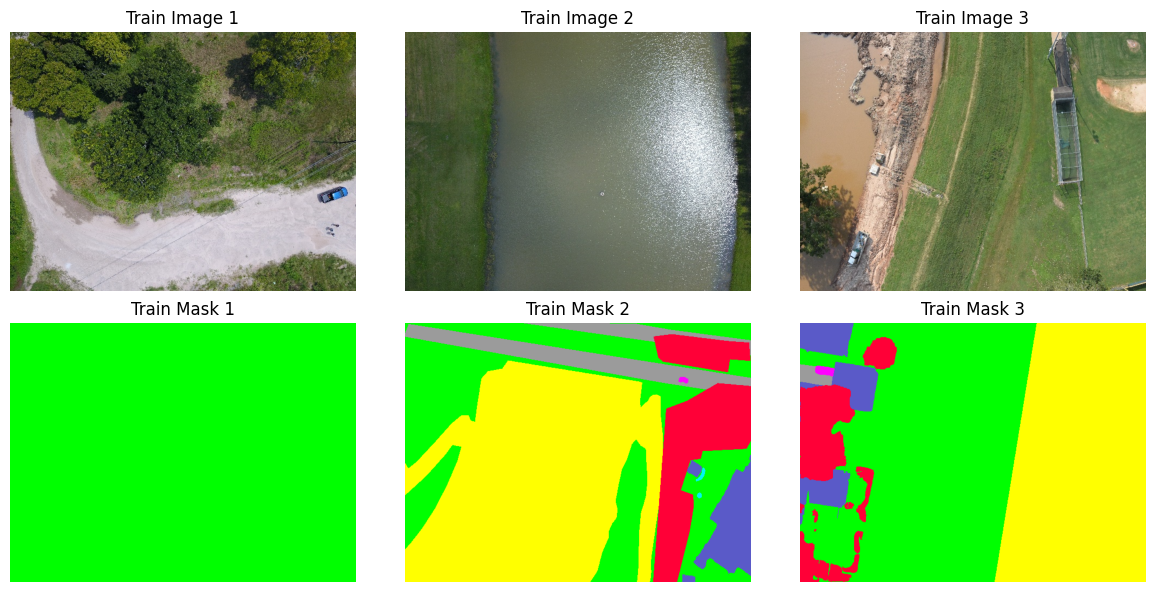

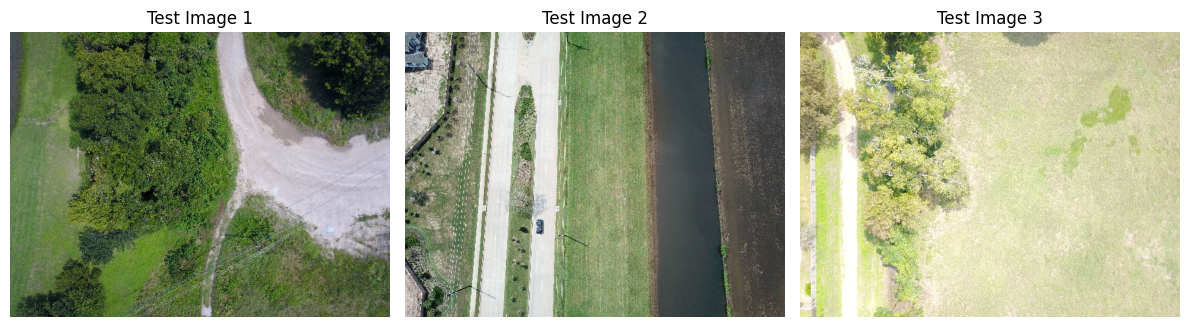

In [44]:
# Helper function to load and display images
def load_image(path, color=True):
    img = cv2.imread(path)
    if color:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img

# Plot first 3 train images and masks
plt.figure(figsize=(12, 6))
for i in range(3):
    img = load_image(train_imgs[i])
    mask = load_image(train_masks[i], color=False)

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(f'Train Image {i+1}')
    plt.axis('off')

    plt.subplot(2, 3, i + 4)
    plt.imshow(mask, cmap='gray')
    plt.title(f'Train Mask {i+1}')
    plt.axis('off')

plt.tight_layout()
plt.show()

# Plot first 3 test images
plt.figure(figsize=(12, 4))
for i in range(3):
    img = load_image(test_imgs[i])

    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(f'Test Image {i+1}')
    plt.axis('off')

plt.tight_layout()
plt.show()


### 2.2.3 Visualize the Dataset

In this section, we plot any 3 images from the training set with their corresponding masks and an overlayed images.

- **Seperate train and valid dataset by 80/20** <br>
    - We have `images` and `masks` in the train folders, so we need to seperate train and valid dataset for both of them.
    - We seperate the train and valid by the ratio of `80/20`.
    - We have `jpg` for the images and `png` for the masks.


In [45]:
# 1. Seperate the images in images folder first, then find their masks in the masks folder.
#train_imgs_paths = os.path.join(ROOT_DIR,'train','images')
#train_masks_paths = os.path.join(ROOT_DIR,'train','masks')

#train_imgs = get_data(train_imgs_paths)
#train_masks = get_data(train_masks_paths)

#train_imgs = glob.glob(train_imgs_paths + '/*')
#train_masks = glob.glob(train_masks_paths + '/*')

# Shuffle the data
random.shuffle(train_imgs)
split_idx = int(0.8 * len(train_imgs))
train_data_path = train_imgs[0:split_idx]
valid_data_path = train_imgs[split_idx:]

print('Preview the first 3 images of train and valid dataset : \n',
      'Train Dataset: ',
      '\n', train_data_path[0:3],'\n',
      'Valid Dataset:',
      '\n', valid_data_path[0:3])

# Get train and valid masks
# Get the file name (the number). e.g. 8190
train_data_names = [ele.split('/')[-1].split('.')[0] for ele in train_data_path]
valid_data_names = [name.split('/')[-1].split('.')[0] for name in valid_data_path]

print('Preview the first 3 names of train and valid dataset : \n',
      'Train Dataset: ',
      '\n', train_data_names[0:3],'\n',
      'Valid Dataset:',
      '\n', valid_data_names[0:3])

def get_masks(fn_list):
    masks = []
    for fn in fn_list:
        masks.append(glob.glob(train_masks_paths + "/" + fn + '.*')[0])

    return masks

# Seperate train and valid for the masks
train_data_masks_path = get_masks(train_data_names)
valid_data_masks_path = get_masks(valid_data_names)

print(train_data_masks_path[0:3],'\n',valid_data_masks_path[0:3])

Preview the first 3 images of train and valid dataset : 
 Train Dataset:  
 ['/kaggle/input/opencv-tf-project-3-image-segmentation-round-2/Project_3_FloodNet_Dataset/train/images/7569.jpg', '/kaggle/input/opencv-tf-project-3-image-segmentation-round-2/Project_3_FloodNet_Dataset/train/images/7688.jpg', '/kaggle/input/opencv-tf-project-3-image-segmentation-round-2/Project_3_FloodNet_Dataset/train/images/8168.jpg'] 
 Valid Dataset: 
 ['/kaggle/input/opencv-tf-project-3-image-segmentation-round-2/Project_3_FloodNet_Dataset/train/images/8080.jpg', '/kaggle/input/opencv-tf-project-3-image-segmentation-round-2/Project_3_FloodNet_Dataset/train/images/7088.jpg', '/kaggle/input/opencv-tf-project-3-image-segmentation-round-2/Project_3_FloodNet_Dataset/train/images/7042.jpg']
Preview the first 3 names of train and valid dataset : 
 Train Dataset:  
 ['7569', '7688', '8168'] 
 Valid Dataset: 
 ['8080', '7088', '7042']
['/kaggle/input/opencv-tf-project-3-image-segmentation-round-2/Project_3_FloodNet

- **Dataset Configurations**

In [46]:
@dataclass(frozen=True)
class DatasetConfig:
    NUM_CLASSES: int = 10
    IMG_WIDTH:   int = 640
    IMG_HEIGHT:  int = 480
      
@dataclass(frozen=True)
class TrainingConfig:
    BATCH_SIZE:      int = 4
    EPOCHS:          int = 50
    LEARNING_RATE: float = 0.0001
    CHECKPOINT_DIR:  str = 'model_checkpoint/p3'
        
@dataclass(frozen=True)
class InferenceConfig:
    NUM_BATCHES:     int = 4

## Map classes to colors
id2color = {
    0:(0, 0, 0),   
    1:(255, 0, 0),
    2:(200, 90, 90),
    3:(128, 128, 0),
    4:(155, 155, 155),
    5:(0, 255, 255),
    6:(55, 0, 255),
    7:(255, 0, 255),
    8:(245, 245, 0),
    9:(0, 255, 0)
 }

- **Helper functions to display the overlayed images**

In [47]:
# Function to one-hot encode RGB mask labels.
def rgb_to_onehot(rgb_arr, color_map=id2color, num_classes=DatasetConfig.NUM_CLASSES):
    
    shape = rgb_arr.shape[:2] + (num_classes,)
    arr = np.zeros( shape, dtype=np.float32 )
    
    for i, classes in enumerate(color_map):
        arr[:,:,i] = np.all(rgb_arr.reshape( (-1,3) ) == color_map[i], axis=1).reshape(shape[:2])
        
    return arr

# Custom Class for creating training and validation (segmentation) dataset objects.
class CustomSegDataLoader(Sequence):
    
    def __init__(self, batch_size, image_size, image_paths , mask_paths , num_classes, aug):
        
        self.batch_size  = batch_size
        self.image_size  = image_size
        self.image_paths = image_paths
        self.mask_paths  = mask_paths
        self.num_classes = num_classes
        self.aug = aug
        
        self.x = np.empty((self.batch_size,) + self.image_size + (3,), dtype="float32")
        self.y = np.empty((self.batch_size,) + self.image_size, dtype="float32")
        
        if self.aug:
            self.train_transforms = self.transforms()
        
        self.resize_transforms = self.resize()
        
    def __len__(self):
        
        return len(self.mask_paths) // self.batch_size

    def transforms(self):
        
        # Data augmentation.
        train_transforms = A.Compose([
            A.HorizontalFlip(p=0.5),
            A.ShiftScaleRotate(scale_limit=0.2, rotate_limit=0, 
                               shift_limit=0.2, p=0.5, border_mode=0),
        ])
        return train_transforms
    
    def resize(self):
        
        resize_transforms = A.Resize(
            height=self.image_size[0], width=self.image_size[1],
            interpolation=cv2.INTER_NEAREST,
            always_apply=True, p=1
        )
        return resize_transforms
    
    def reset_array(self):
        self.x.fill(0.)
        self.y.fill(0.)

    def __getitem__(self, idx):
        self.reset_array()
        i = idx * self.batch_size
        batch_image_paths = self.image_paths[i : i + self.batch_size]
        batch_mask_paths = self.mask_paths[i : i + self.batch_size]
        
        for j, (input_image, input_mask) in enumerate(zip(batch_image_paths, batch_mask_paths)):

            # Read the image and convert to RGB.
            img = cv2.imread(input_image)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
     
            # Read the mask and convert to RGB.
            msk = cv2.imread(input_mask)
            msk = cv2.cvtColor(msk, cv2.COLOR_BGR2RGB)

            # Resize the image and mask.
            resized  = self.resize_transforms(image=img, mask=msk)
            img, msk = resized['image'], resized['mask']
            
            if self.aug:
                # Apply augmentations.
                train_augment = self.train_transforms(image=img, mask=msk)
                img, msk = train_augment['image'], train_augment['mask']

            # Store image in x.
            self.x[j] = img 
            msk = rgb_to_onehot(msk)
            
        
            self.y[j] = msk.argmax(-1)
            
        return self.x, self.y

# Function to convert a single channel mask representation to an RGB mask.
def num_to_rgb(num_arr, color_map=id2color):
    
    single_layer = np.squeeze(num_arr)
    output = np.zeros(num_arr.shape[:2]+(3,))
    
    for k in color_map.keys():
        output[single_layer==k] = color_map[k]
        
    return np.float32(output) / 255. # return a floating point array in range [0.0, 1.0]


# Function to overlay a segmentation map on top of an RGB image.
def image_overlay(image, segmented_image):
    
    alpha = 1.0 # Transparency for the original image.
    beta  = 0.4 # Transparency for the segmentation map.
    gamma = 0.0 # Scalar added to each sum.
    
    segmented_image = cv2.cvtColor(segmented_image, cv2.COLOR_RGB2BGR)
    
    image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
    
    image = cv2.addWeighted(image, alpha, segmented_image, beta, gamma, image)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    return np.clip(image, 0.0, 1.0)

def display_image_and_mask(data_list, color_mask=False, color_map=id2color):
    
    plt.figure(figsize=(16, 6))
    title = ['GT Image', 'GT Mask', 'Overlayed Mask']

    grayscale_gt_mask = data_list[1]
    
    # Create RGB segmentation map from grayscale segmentation map.
    rgb_gt_mask = num_to_rgb(data_list[1], color_map=color_map)
    
    # Create the overlayed image.
    overlayed_image = image_overlay(data_list[0], rgb_gt_mask)
    
    data_list.append(overlayed_image)
    
    for i in range(len(data_list)):
        plt.subplot(1, len(data_list), i+1)
        plt.title(title[i])
        if title[i] == 'GT Mask':
            if color_mask:
                plt.imshow(np.array(rgb_gt_mask))
            else:
                plt.imshow(np.array(grayscale_gt_mask))
        else:
            plt.imshow(np.array(data_list[i]))
        plt.axis('off')
        
    plt.show()
    
def create_datasets(aug=False):
    
    # Train data loader.
    train_ds = CustomSegDataLoader(batch_size=TrainingConfig.BATCH_SIZE,
                                   image_size=(DatasetConfig.IMG_HEIGHT, DatasetConfig.IMG_WIDTH),
                                   image_paths=train_data_path,
                                   mask_paths=train_data_masks_path,
                                   num_classes=DatasetConfig.NUM_CLASSES,
                                   aug=aug,
                                  )
    # Validation data loader.
    valid_ds = CustomSegDataLoader(batch_size=TrainingConfig.BATCH_SIZE,
                                   image_size=(DatasetConfig.IMG_HEIGHT, DatasetConfig.IMG_WIDTH),
                                   image_paths=valid_data_path,
                                   mask_paths=valid_data_masks_path,
                                   num_classes=DatasetConfig.NUM_CLASSES,
                                   aug=False,
                                  )
    
    return train_ds, valid_ds

/tmp/ipykernel_36/3772468667.py:48: UserWarning: Argument(s) 'always_apply' are not valid for transform Resize
  resize_transforms = A.Resize(


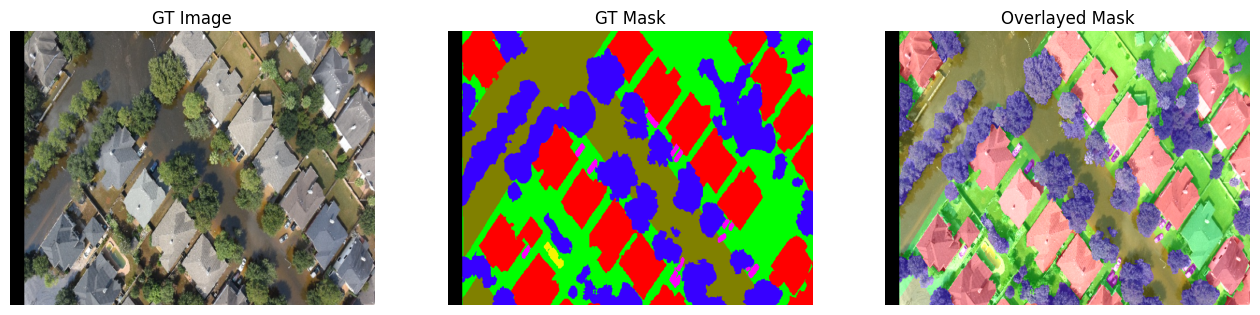

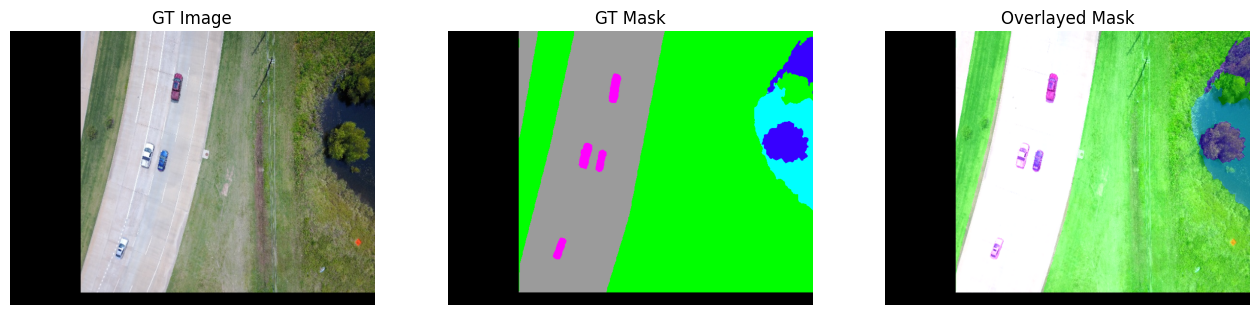

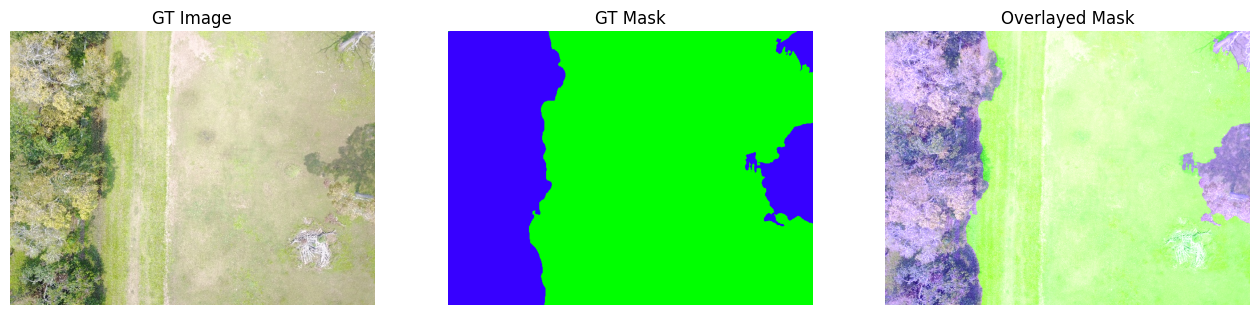

In [48]:
train_ds, valid_ds = create_datasets(aug=True)

for i, (images, masks) in enumerate(train_ds):
    if i == 3:
        break
    image, mask = images[0], masks[0]
    display_image_and_mask([image/255.0, mask], # Image and Mask in same pixel value range [0.0, 1.0] for display. 
                           color_mask=True)

# 3. Modeling
## 3.1 The Choise of Loss Function

FloodNet is a semantic segmentation task with pixel-level classification, often involving class imbalance—for example, flooded areas might occupy a small fraction of the image compared to background or vegetation. Dice loss directly addresses this challenge:
- Dice loss measures overlap between predicted and ground truth masks using the Dice coefficient, which is especially sensitive to small regions.
- It prioritizes accurate segmentation of minority classes (like flooded roads or damaged buildings) by focusing on the quality of overlap rather than raw pixel counts.
- It’s robust when some classes are underrepresented, which is common in disaster datasets.



In [49]:
def dice_coef_loss(y_true, y_pred):
    """
    Arguments:
    y_true (ndarray or tensor): Ground truth mask (G). Shape: (batch_size, height, width)
                                Sparse representation of segmentation mask.

    y_pred (ndarray or tensor): Softmax prediction (P) from the model.
                                Shape: (batch_size, height, width, num_classes).

    return (scalar): Loss
    """
    num_classes = y_pred.shape[-1]
    
    # Convert single channel ground truth labels to one-hot encoding for metric computation.
    y_true = tf.one_hot(tf.cast(y_true, tf.int32), num_classes, axis=-1)
    
    # Axes corresponding to image width and height: [B, H, W, C].
    axes = (1, 2)
    
    # Intersection: |G ∩ P|. Shape: (batch_size, num_classes)
    intersection = tf.math.reduce_sum(y_true * y_pred, axis=axes)
    
    # Total Sum: |G| + |P|. Shape: (batch_size, num_classes)
    total = tf.math.reduce_sum(y_true, axis=axes) + tf.math.reduce_sum(y_pred, axis=axes)
    
    # Dice coefficient. Shape: (batch_size, num_classes)
    eps = 1e-3
    dc = (2. *  intersection + eps) / (total + eps)
    
    # Compute the mean over the remaining axes (batch and classes).
    dc_mean = tf.math.reduce_mean(dc)
    
    # Compute cross-entropy loss.
    CCE =  tf.keras.losses.categorical_crossentropy(y_true, y_pred)
    
    return 1.0 - dc_mean + CCE

## 3.2 Evaluation Metrics

This competition is evaluated on the mean <a href="https://en.wikipedia.org/wiki/Sørensen–Dice_coefficient" target="_blank">Dice coefficient</a>,  which helps compare the pixel-wise agreement between a predicted segmentation and its corresponding ground truth.


In [50]:
def mean_iou(y_true, y_pred):
    """
    Arguments:
    y_true (ndarray or tensor): Ground truth mask (G). Shape: (batch_size, height, width)
                               Sparse representation of segmentation mask.

    y_pred (ndarray or tensor): Prediction (P) from the model with or without softmax.
                                Shape: (batch_size, height, width, num_classes).

    return (scalar): Classwise mean IoU Metric.
    """
    
    # Get total number of classes from model output.
    num_classes = y_pred.shape[-1]

    # Convert single channel (sparse) ground truth labels to one-hot encoding for metric computation.
    y_true = tf.one_hot(tf.cast(y_true, tf.int32), num_classes, axis=-1)

    # Convert multi-channel predicted output to one-hot encoded thresholded output for metric computation. 
    y_pred = tf.one_hot(tf.math.argmax(y_pred, axis=-1), num_classes, axis=-1)

    # Axes corresponding to image width and height: [B, H, W, C].
    axes = (1, 2)

    # Intersection: |G ∩ P|. Shape: (batch_size, num_classes)
    intersection = tf.math.reduce_sum(y_true * y_pred, axis=axes)

    # Total Sum: |G| + |P|. Shape: (batch_size, num_classes)
    total = tf.math.reduce_sum(y_true, axis=axes) + tf.math.reduce_sum(y_pred, axis=axes)

    # Union: Shape: (batch_size, num_classes)
    union = total - intersection

    # Boolean (then converted to float) value for each class if it is present or not. 
    # Shape: (batch_size, num_classes)
    is_class_present =  tf.cast(tf.math.not_equal(total, 0), dtype=tf.float32)

    # Sum along axis(1) to get number of classes in each image.
    # Shape: (batch_size,)
    num_classes_present = tf.math.reduce_sum(is_class_present, axis=1)

    # Here, we use tf.math.divide_no_nan() to prevent division by 0 (i.e., 0/0 = 0).
    # Shape: (batch_size, num_classes)
    iou = tf.math.divide_no_nan(intersection, union)

    # IoU per image. Average over the total number of classes present in y_true and y_pred.
    # Shape: (batch_size,)
    iou = tf.math.reduce_sum(iou, axis=1) / num_classes_present
    
    # Compute the mean across the batch axis. Shape: Scalar
    mean_iou = tf.math.reduce_mean(iou)
    
    return mean_iou

In [51]:
# Create a new checkpoint directory every time.
if not os.path.exists(TrainingConfig.CHECKPOINT_DIR):
    os.makedirs(TrainingConfig.CHECKPOINT_DIR)
    
num_versions = len(os.listdir(TrainingConfig.CHECKPOINT_DIR)) + 1
version_dir = TrainingConfig.CHECKPOINT_DIR +'/version_' + str(num_versions)
os.makedirs(version_dir)

# Callback to save the best model based on validation loss.
model_path = os.path.join(version_dir, 'best_model.keras')
model_checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=model_path,
    save_weights_only=False,
    monitor='val_mean_iou',
    mode='max',
    save_best_only=True
)


## 3.3 The Choise of Model

For this project, DeepLabV3+ was selected as the core segmentation architecture due to its strong performance in handling complex, high-resolution imagery and its ability to capture multi-scale contextual features. FloodNet presents challenges such as class imbalance, subtle flood boundaries, and diverse object scales—all of which DeepLabV3+ is well-equipped to address.

Key reasons for choosing DeepLabV3+ include:

- **Multi-scale feature extraction**: The Atrous Spatial Pyramid Pooling (ASPP) module captures both fine and coarse features, essential for identifying small flooded zones and large water bodies.
- **Boundary refinement**: The decoder module improves edge precision, which is critical for distinguishing between flooded and non-flooded regions.
- **Strong backbone**: ResNet50 provides robust hierarchical features, pretrained on ImageNet and fine-tuned for aerial flood scenes.
- **Modular design**: Custom convolution blocks with batch normalization and dropout enhance stability and generalization.
- **End-to-end trainability**: All layers are trainable, allowing full adaptation to FloodNet’s domain-specific characteristics.
- **Softmax output**: Supports multi-class segmentation, enabling accurate labeling of roads, buildings, vegetation, and water.

This architecture balances global context with local detail, making it a principled and practical choice for post-flood scene understanding.



In [52]:
def convolution_block(block_input,
                      num_filters=256,
                      kernel_size=3,
                      dilation_rate=1,
                      padding="same",
                      use_bias=False):
    
    x = Conv2D(num_filters, kernel_size=kernel_size, 
               dilation_rate=dilation_rate, padding="same", use_bias=use_bias)(block_input)
        
    x = BatchNormalization()(x)

    x = Dropout(0.2)(x)

    return Activation('relu')(x)

def DilatedSpatialPyramidPooling(dspp_input):
    
    dims = dspp_input.shape
    # Create a 1x1 feature map using AveragePooling2D.
    x = AveragePooling2D(pool_size=(dims[1], dims[2]))(dspp_input)
    x = convolution_block(x, kernel_size=1, use_bias=True)
    
    # Upsample the feature map to the original size.
    out_pool = UpSampling2D(size=(dims[1], dims[2]), interpolation="bilinear")(x)

    # Create feature maps of the same shape with different dilation rates.
    out_1  = convolution_block(dspp_input, kernel_size=1, dilation_rate=1)
    out_6  = convolution_block(dspp_input, kernel_size=3, dilation_rate=6)
    out_12 = convolution_block(dspp_input, kernel_size=3, dilation_rate=12)
    out_18 = convolution_block(dspp_input, kernel_size=3, dilation_rate=18)

    # Combine all the feature maps and process them through a 1x1 convolutional block.
    x = Concatenate(axis=-1)([out_pool, out_1, out_6, out_12, out_18])
    output = convolution_block(x, kernel_size=1)
    
    return output

def deeplabv3plus(num_classes, shape):
    
    model_input = Input(shape=shape)
    preprocessing = preprocess_input(model_input)
    backbone = ResNet50(weights="imagenet", include_top=False, input_tensor=preprocessing)
    
    # Set all layers in the backbone as trainable.
    for layer in backbone.layers:
        layer.trainable = True

    # Obtain a (lower resolution) feature map from the backbone. 
    # Shape: (16, 16, 512)
    input_a = backbone.get_layer('conv5_block3_2_relu').output
    
    # Pass through Atrous Spatial Pooling to obtain the best features at various scales.
    input_a = DilatedSpatialPyramidPooling(input_a)
    
    # Upsample the concatenated features.
    input_a = UpSampling2D(size=(16, 16), interpolation="bilinear")(input_a)
        
    # Obtain a second (lower resolution) feature map from the backbone. 
    # Shape: (32, 32, 256)
    input_b = backbone.get_layer("conv4_block6_2_relu").output
    
    # Pass through Atrous Spatial Pooling to obtain the best features at various scales.
    input_b = DilatedSpatialPyramidPooling(input_b)
    
    # Upsample the concatenated features.
    input_b = UpSampling2D(size=(8, 8), interpolation="bilinear")(input_b)
    
    # Obtain a third (higher resolution) feature map from the backbone and apply convolution. 
    # Shape: (128, 128, 64)
    input_c = backbone.get_layer("conv2_block3_2_relu").output
    input_c = convolution_block(input_c, num_filters=256, kernel_size=1)
    input_c = UpSampling2D((2, 2), interpolation='bilinear')(input_c)
    
    # Obtain a fourth (higher resolution) feature map from the backbone and apply convolution.
    # Shape: (256, 256, 64)
    input_d = backbone.get_layer("conv1_relu").output
    input_d = convolution_block(input_d, num_filters=256, kernel_size=1)

    # Concatenate all four feature maps and apply convolution 2 more times.
    x = Concatenate(axis=-1)([input_a, input_b, input_c, input_d])
    
    x = convolution_block(x)
    x = convolution_block(x)
    x = UpSampling2D(size=(shape[0] // x.shape[1], 
                           shape[1] // x.shape[2]), interpolation="bilinear")(x)

    # Apply 1x1 convolution to limit the depth of the feature maps to the number of classes.
    outputs = Conv2D(num_classes, kernel_size=(1, 1), padding="same")(x)

    model_output = Activation('softmax')(outputs)

    model = Model(inputs=model_input, outputs=model_output)
    
    return model

In [53]:
model = deeplabv3plus(num_classes=DatasetConfig.NUM_CLASSES, shape=(DatasetConfig.IMG_HEIGHT, DatasetConfig.IMG_WIDTH, 3))
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 480, 640,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_3          │ (None, 480, 640)  │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_4          │ (None, 480, 640)  │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_5          │ (None, 480, 640)  │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_1 (Stack)     │ (None, 480, 640,  │          0 │ get_item_3[0][0], │
│                     │ 3)                │            │ get_item_4[0][0], │
│                     │                   │            │ get_item_5[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 480, 640,  │          0 │ stack_1[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 486, 646,  │          0 │ add_1[0][0]       │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 240, 320,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 240, 320,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 240, 320,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 242, 322,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 120, 160,  │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 120, 160,  │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 120, 160,  │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 120, 160,  │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 120, 160,  │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 31,887,242 (121.64 MB)

 Trainable params: 31,830,026 (121.42 MB)

 Non-trainable params: 57,216 (223.50 KB)

# 4. Train and Plot Results
## 4.1 Training

In [54]:
# Create a new checkpoint directory every time.
if not os.path.exists(TrainingConfig.CHECKPOINT_DIR):
    os.makedirs(TrainingConfig.CHECKPOINT_DIR)

num_versions = len(os.listdir(TrainingConfig.CHECKPOINT_DIR)) + 1
version_dir = TrainingConfig.CHECKPOINT_DIR + '/version_' + str(num_versions)
os.makedirs(version_dir)

# Define full model file path with .keras extension
model_path = os.path.join(version_dir, 'best_model.keras')

# Callback to save the best model based on validation loss.
model_checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=model_path,
    save_weights_only=False,
    monitor='val_mean_iou',
    mode='max',
    save_best_only=True,
)


model.compile(optimizer=Adam(learning_rate=TrainingConfig.LEARNING_RATE), 
              loss=dice_coef_loss,
              metrics=['accuracy', mean_iou],
             )

history = model.fit(train_ds,
                    epochs=TrainingConfig.EPOCHS, 
                    verbose=1,
                    validation_data=valid_ds,
                    callbacks=[model_checkpoint_callback],
                   )

737/737 ━━━━━━━━━━━━━━━━━━━━ 826s 969ms/step - accuracy: 0.7059 - loss: 1.7919 - mean_iou: 0.2493 - val_accuracy: 0.0909 - val_loss: 267.7320 - val_mean_iou: 0.0253


## 4.2 Plot the result

In [55]:
def plot_results(metrics, ylabel=None, ylim=None, metric_name=None, color=None):
    
    fig, ax = plt.subplots(figsize=(18, 5))

    if not (isinstance(metric_name, list) or isinstance(metric_name, tuple)):
        metrics = [metrics,]
        metric_name = [metric_name,]
        
    for idx, metric in enumerate(metrics):    
        ax.plot(metric, color=color[idx])
    
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(ylabel)
    plt.xlim([0, TrainingConfig.EPOCHS-1])
    plt.ylim(ylim)
    # Tailor x-axis tick marks
    ax.xaxis.set_major_locator(MultipleLocator(5))
    ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))
    ax.xaxis.set_minor_locator(MultipleLocator(1))
    plt.grid(True)
    plt.legend(metric_name)   
    plt.show(block=block_plot)
    plt.close()

/tmp/ipykernel_36/3684165712.py:15: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  plt.xlim([0, TrainingConfig.EPOCHS-1])


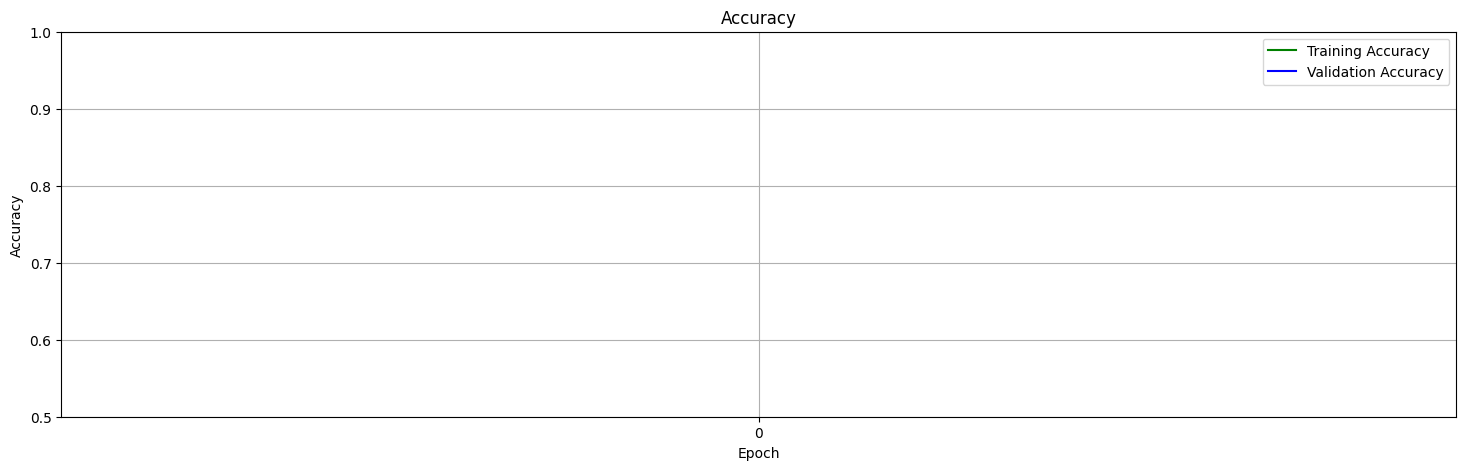

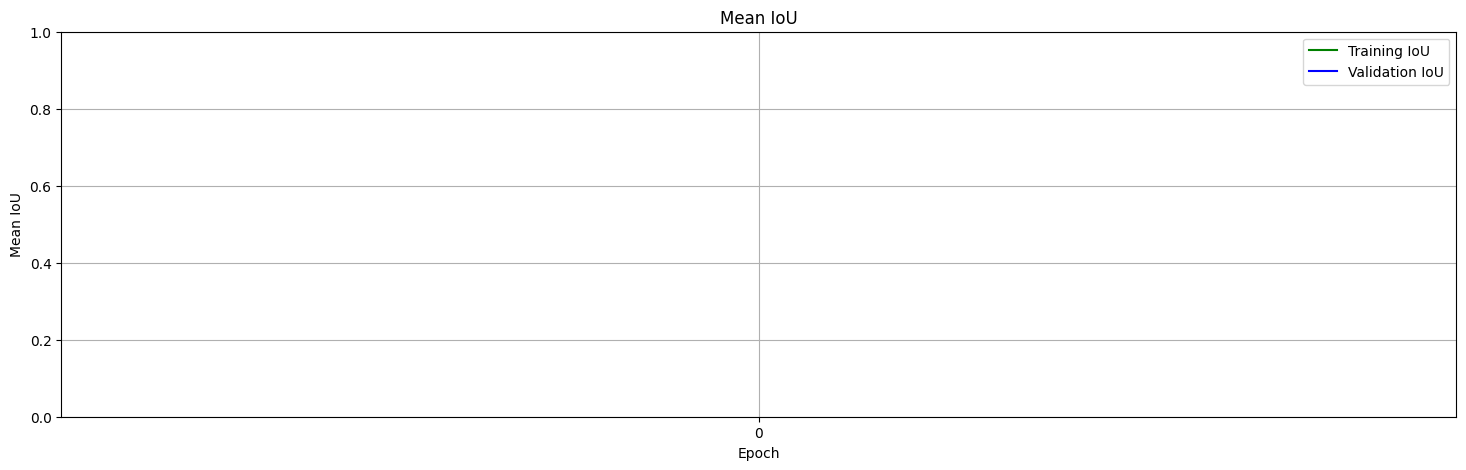

In [56]:
# Pixel accuracy
train_acc = history.history["accuracy"]
valid_acc = history.history["val_accuracy"]

# Mean IoU.
train_iou = history.history["mean_iou"]
valid_iou = history.history["val_mean_iou"]

    
plot_results([ train_acc, valid_acc ], 
            ylabel="Accuracy",
            ylim = [0.5, 1.0],
            metric_name=["Training Accuracy", "Validation Accuracy"],
            color=["g", "b"])

plot_results([ train_iou, valid_iou ], 
            ylabel="Mean IoU",
            ylim = [0.0, 1.0],
            metric_name=["Training IoU", "Validation IoU"],
            color=["g", "b"])

/tmp/ipykernel_36/3684165712.py:15: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  plt.xlim([0, TrainingConfig.EPOCHS-1])


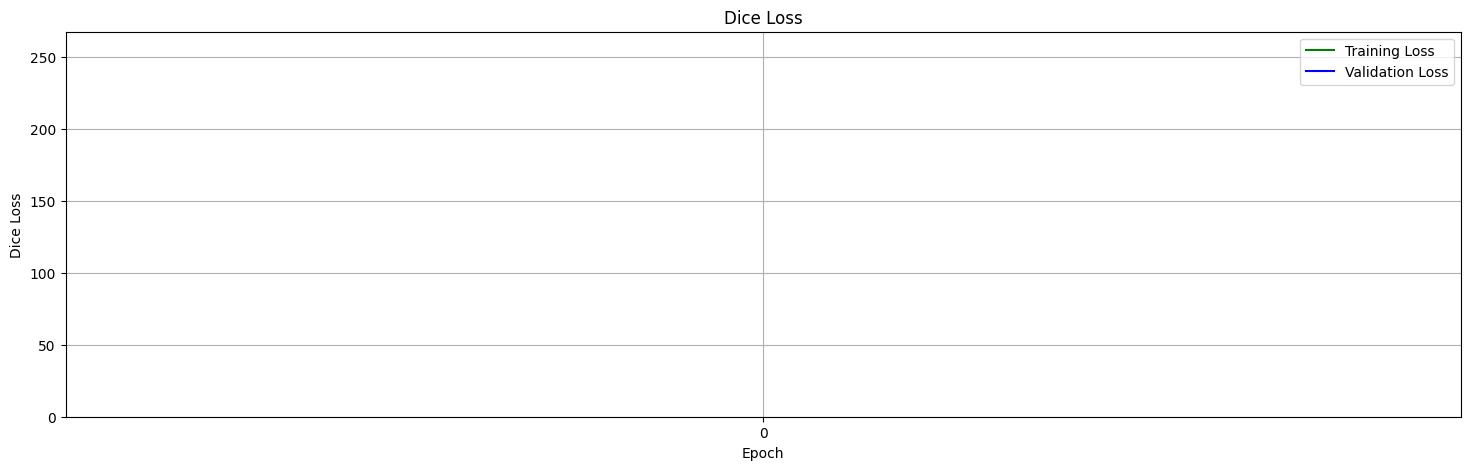

In [57]:
train_loss = history.history["loss"]
valid_loss = history.history["val_loss"]


max_loss = max(max(train_loss), max(valid_loss))

plot_results([ train_loss, valid_loss ],        
            ylabel="Dice Loss", 
            ylim = [0.0, max_loss],
            metric_name=["Training Loss", "Validation Loss"],
            color=["g", "b"]);

# 5. Inference

In [59]:
trained_model = tf.keras.models.load_model(
    model_path,
    custom_objects={'mean_iou': mean_iou, 'dice_coef_loss': dice_coef_loss}
)

In [60]:
evaluate = trained_model.evaluate(valid_ds)

print(f"Model evaluation accuracy:  {evaluate[1]*100.:.3f}")
print(f"Model evaluation mean IoU:  {evaluate[2]*100.:.3f}")

184/184 ━━━━━━━━━━━━━━━━━━━━ 68s 303ms/step - accuracy: 0.2154 - loss: 140.6131 - mean_iou: 0.0529
Model evaluation accuracy:  22.968
Model evaluation mean IoU:  5.466


In [61]:
def inference(model, dataset):

    num_batches_to_process = 2

    for idx, data in enumerate(dataset):
        
        batch_img, batch_mask = data[0], data[1]
        pred_all = (model.predict(batch_img)).astype('float32')
        pred_all = pred_all.argmax(-1)
        #batch_img = (batch_img).astype('uint8')
        if idx == num_batches_to_process:
            break

        for i in range(0, len(batch_img)):
            
            fig = plt.figure(figsize=(20, 8))
            
            # Display the original image.
            ax1 = fig.add_subplot(1,4,1)
            ax1.imshow(batch_img[i].astype('uint8'))
            ax1.title.set_text('Actual frame')
            plt.axis('off')
            
            # Display the ground truth mask.
            true_mask_rgb = num_to_rgb(batch_mask[i], color_map=id2color)
            ax2 = fig.add_subplot(1,4,2)
            ax2.set_title('Ground truth labels')
            ax2.imshow(true_mask_rgb)
            plt.axis('off')
            
            # Display the predicted segmentation mask. 
            pred_mask_rgb = num_to_rgb(pred_all[i], color_map=id2color)
            ax3 = fig.add_subplot(1,4,3)
            ax3.set_title('Predicted labels')
            ax3.imshow(pred_mask_rgb)
            plt.axis('off')

            # Display the predicted segmentation mask overlayed on the original image.
            overlayed_image = image_overlay(batch_img[i]/255.0, pred_mask_rgb)
            ax4 = fig.add_subplot(1,4,4)
            ax4.set_title('Overlayed image')
            ax4.imshow(overlayed_image)
            plt.axis('off')
            
            plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step


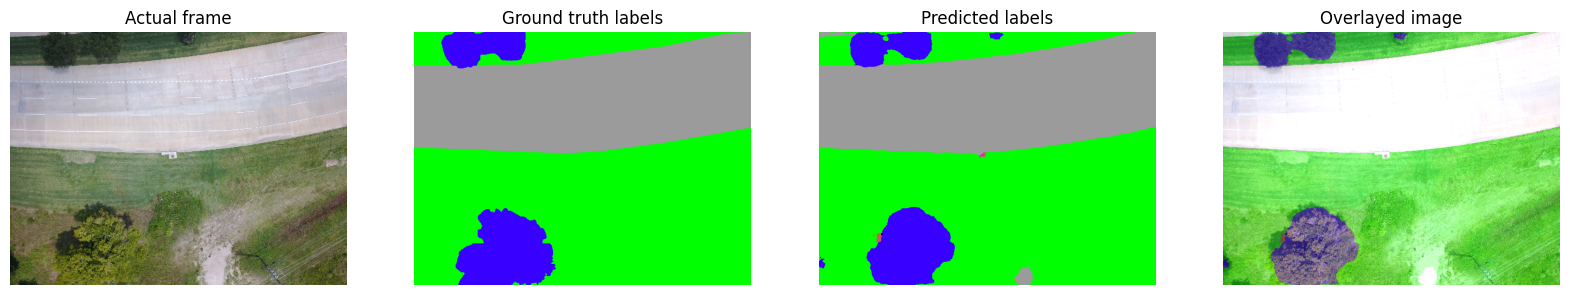

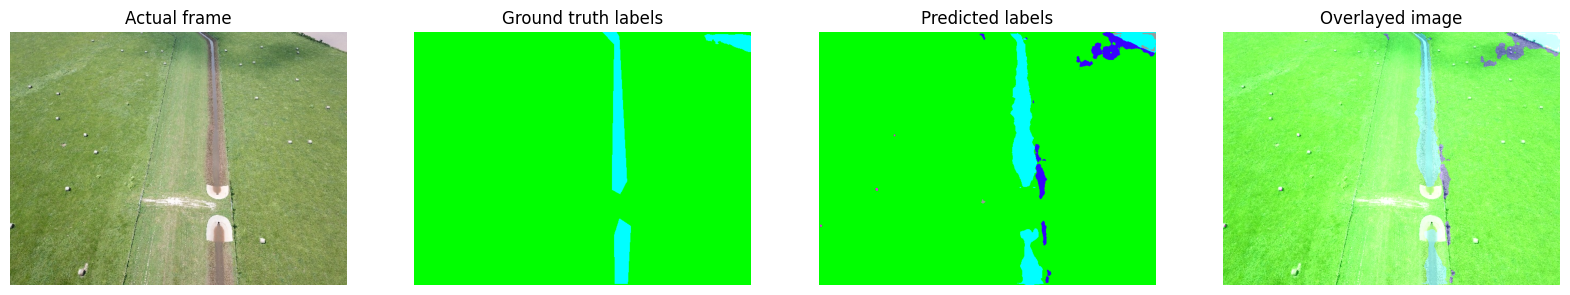

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 441ms/step


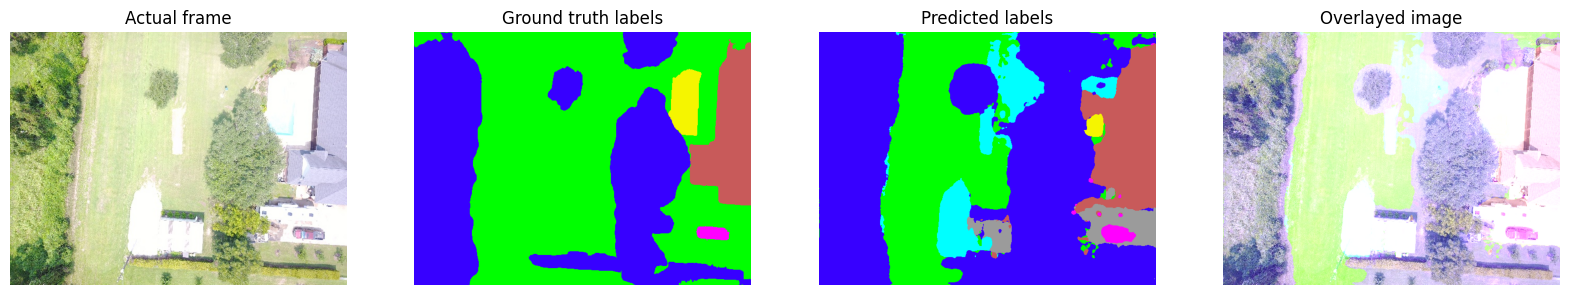

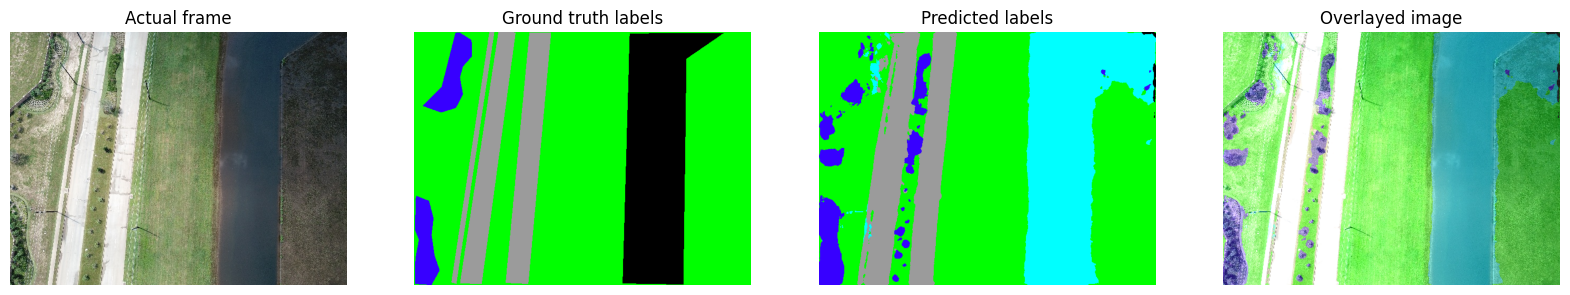

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 343ms/step


In [62]:
inference(trained_model, valid_ds)

In [63]:
# Custom Class for creating training and validation (segmentation) dataset objects.
class get_testds(Sequence):
    
    def __init__(self, batch_size, image_size, image_paths ):
        
        self.batch_size  = batch_size
        self.image_size  = image_size
        self.image_paths = image_paths

        
        self.x = np.empty((self.batch_size,) + self.image_size + (3,), dtype="float32")
        
        self.resize_transforms = self.resize()
        
    def __len__(self):
        
        return len(self.image_paths) // self.batch_size

    
    def resize(self):
        
        resize_transforms = A.Resize(
            height=self.image_size[0], width=self.image_size[1],
            interpolation=cv2.INTER_NEAREST,
            always_apply=True, p=1
        )
        return resize_transforms
    
    def reset_array(self):
        self.x.fill(0.)


    def __getitem__(self, idx):
        self.reset_array()
        i = idx * self.batch_size
        batch_image_paths = self.image_paths[i : i + self.batch_size]
        
        for j, input_image in enumerate(batch_image_paths):

            # Read the image and convert to RGB.
            img = cv2.imread(input_image)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


            # Resize the image and mask.
            resized  = self.resize_transforms(image=img)
            img = resized['image']
            


            # Store image in x.
            self.x[j] = img # Image Normalization not done because the pretrained ResNet model 
                            # requires it's own preprocess_input function.
     
        return self.x



In [66]:
test_ds = get_testds(batch_size=TrainingConfig.BATCH_SIZE,image_size=(DatasetConfig.IMG_HEIGHT, DatasetConfig.IMG_WIDTH),image_paths=test_imgs)

/tmp/ipykernel_36/2370449480.py:22: UserWarning: Argument(s) 'always_apply' are not valid for transform Resize
  resize_transforms = A.Resize(


# 6. Prepare Submission CSV

**Prepare for the IMG_ID**

In [67]:
img_id = np.array([])
for item in test_imgs:
    fn = item.split('/')[-1].split('.')[0]
    for i in range(10):
        full_fn = fn + '_0{}'.format(i)
        img_id = np.append(img_id,full_fn)

print('The 5 names for the first test image :','\n',img_id[:5],'\n','\nThe length of IMG_ID : ',len(img_id))

The 5 names for the first test image : 
 ['7894_00' '7894_01' '7894_02' '7894_03' '7894_04'] 
 
The length of IMG_ID :  5000


**Prepare for the Encodedstring**

In [68]:
def get_one_hot(mask):

    # Find the index of the maximum value
    idx = np.argmax(mask)
    #print(idx)

    # Create a new array of zeros with the same shape as the original array
    new_array = np.zeros_like(mask)

    # Set the maximum value to 1
    new_array[idx] = 1

    return new_array

def mask2rle(img):

    pixels = img.T.flatten()
    pixels = np.pad(pixels, ((1, 1), ))
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1
    runs[1::2] -= runs[::2]
    return ' '.join(str(x) for x in runs)

mask = np.array([])

for idx,data in enumerate(test_ds):
    tmp_msk = np.array([])
    result = model.predict(data)
    for ele in result:
        for i in range(ele.shape[0]):
            for j in range(ele.shape[1]):
                ele[i][j] = get_one_hot(ele[i][j])
        
        #Iterate each channel:
        for c in range(10):
            tmp_msk = np.append(tmp_msk,mask2rle(ele[:,:,c]))
    mask = np.append(mask,tmp_msk)

1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 420ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 418ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 430ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 408ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 401ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 427ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 422ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 417ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 404ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 422ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 393ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 430ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 424ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 391ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 389ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 426ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 389ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 415ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 422ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 408ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 415ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 398ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 399ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

In [ ]:
import pandas as pd
d = {
    'IMG_ID':img_id,
    'EncodedString':mask,
}
df = pd.DataFrame(d)
df.to_csv('/kaggle/working/submission.csv')

df = pd.read_csv("submission.csv")
df.drop(["Unnamed: 0"], axis=1, inplace=True)
df.to_csv("fixed_submission.csv", index=False)

# 7. Discussion and Conclusion

1. **Model Comparison**

    While DeepLabV3+ was the primary architecture used in this project, it’s worth comparing it to other popular segmentation models:
    
| Model        | Strengths                                             | Limitations                                           |
|--------------|-------------------------------------------------------|-------------------------------------------------------|
| **U-Net**    | Lightweight, fast convergence, strong for medical and binary segmentation | Struggles with complex multi-class scenes and large-scale context |
| **HRNet**    | Maintains high-resolution features throughout; excellent for fine-grained segmentation | Computationally expensive; harder to integrate with pretrained backbones |
| **DeepLabV3+** | Captures multi-scale context via ASPP; refines boundaries with decoder; modular and extensible | Slightly heavier than U-Net; slower inference on edge devices |
    
    DeepLabV3+ strikes a balance between global context and local precision, making it especially suitable for aerial flood imagery where both large-scale water bodies and fine-grained infrastructure details must be segmented accurately.


2. **Further Steps**

    To improve performance and robustness, the following steps are recommended:
    
    - **Loss Function Tuning**: Experiment with hybrid loss functions (e.g., Dice + Focal) to better handle class imbalance.
    - **Data Augmentation**: Introduce geometric and photometric augmentations to improve generalization.
    - **Class Weighting**: Apply class weights during training to emphasize underrepresented flood categories.
    - **Post-Processing**: Use Conditional Random Fields (CRFs) or morphological operations to refine mask edges.
    - **Benchmarking**: Compare performance across models using metrics like mIoU, precision, recall, and inference time.

<br>

3. **Conclusion**

    This project successfully implemented DeepLabV3+ for semantic segmentation on the FloodNet dataset. The model demonstrated strong capability in capturing multi-scale features and refining segmentation boundaries, making it a principled choice for post-disaster scene understanding. With further tuning and augmentation, this pipeline can be extended to real-time flood mapping, infrastructure damage assessment, and other critical applications in environmental monitoring and disaster response.

